# Causal effects by posterior g-computation

An outcome regression can answer a causal question only when its adjustment and
identification assumptions are defensible. This tutorial makes those assumptions
and the population being averaged over explicit. It covers standardized outcomes,
ATE, ATT, ATU, CATE, GATE, risk differences, marginal risk ratios, marginal odds
ratios, continuous mean differences and dose-response curves.

We fit two small, seeded models: a Gaussian model with known-group effects and a
Bernoulli model with a named event. Every fitted-model effect below uses those
actual posterior draws. The separate hand-worked examples explain the estimands;
they are not presented as sampling results or as validation of the fitted models.

The computations use expected outcomes from `Model.predict`, not simulated future
outcomes. Posterior uncertainty is **conditional on the supplied, fixed reference
population**. It excludes uncertainty about how that population was sampled.


In [1]:
import bambi as bmb
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

from bambi.causal import g_computation, plot_effects

rng = np.random.default_rng(1055)


## State the causal question before fitting

Our synthetic population has a pretreatment covariate `x`, a pretreatment stratum
`z`, and a site recorded before treatment. The exposure is `dose`, followed by the
outcome `y`. We assume that these variables suffice to adjust the exposure-outcome
relationship: no unmeasured common causes, no post-treatment adjustment, consistent
interventions, overlap at the requested doses, and an adequate outcome model.
These are scientific assumptions; passing the API's checks does not establish them.

For a draw $s$, write $m_s(a,l)=E[Y\mid A=a,L=l,\theta_s]$. For fixed reference
rows and normalized weights, standardization is
$M_s(a)=\sum_i w_i m_s(a,l_i)$. Differences or ratios are formed **within each
posterior draw, after the required standardization**, then summarized.

The six required declarations are `treatment`, `outcome`, `adjustment_set`,
`temporal_order`, `estimand`, and `reference_population`. We also supply the
intervention values. The adjustment set must match every other model covariate,
including group factors. The declared ordering is a consistency check, not a DAG
or an automated identification procedure.


In [2]:
n = 128
site = pd.Categorical(np.tile(["north", "south", "east", "west"], n // 4))
x = rng.normal(size=n)
z = rng.integers(0, 2, size=n)
dose = rng.choice([0.0, 0.5, 1.0], size=n, p=[0.35, 0.3, 0.35])
site_effect = np.array([-0.3, 0.2, 0.4, -0.2])[site.codes]
y = 0.5 + (1 + 1.2 * z) * dose + 0.6 * x + site_effect + rng.normal(0, 0.6, n)
data = pd.DataFrame({"y": y, "dose": dose, "x": x, "z": z, "site": site})

model = bmb.Model("y ~ dose * z + x + (1 | site)", data, family="gaussian")
idata = model.fit(
    draws=250, tune=250, chains=2, cores=1,
    random_seed=105501, target_accept=0.95,
)


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [sigma, Intercept, dose, z, dose:z, x, 1|site_sigma, 1|site_offset]


Output()

Sampling 2 chains for 250 tune and 250 draw iterations (500 + 500 draws total) took 1 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


These are genuine NUTS fits, kept small to make the example practical. Small fits
can have Monte Carlo error and are not evidence that a real analysis is adequately
sampled. Inspect the actual sampler diagnostics and traces, increase sampling when
needed, and investigate divergences rather than interpreting them as causal effects.
The known sites remain in the reference population; we do not sample new groups.


Gaussian posterior dimensions: {'chain': 2, 'draw': 250, 'site__factor_dim': 4}
Gaussian divergences: 0


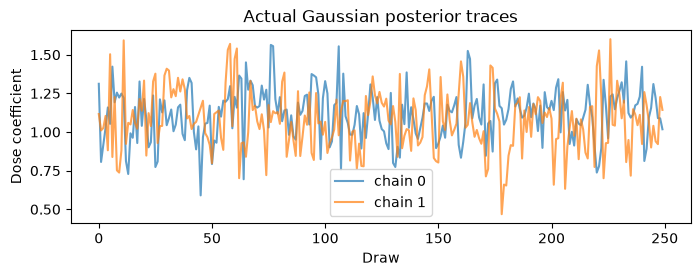

In [3]:
def dataset(group):
    """Access the Dataset stored by a PyMC DataTree group."""
    return group.ds if hasattr(group, "ds") else group

posterior = dataset(idata.posterior)
sample_stats = dataset(idata.sample_stats)
assert posterior.sizes["chain"] == 2 and posterior.sizes["draw"] == 250
print("Gaussian posterior dimensions:", dict(posterior.sizes))
print("Gaussian divergences:", int(sample_stats["diverging"].sum()))
fig, ax = plt.subplots(figsize=(8, 2.5))
for chain in posterior.chain.values:
    ax.plot(posterior["dose"].sel(chain=chain).values, alpha=0.7, label=f"chain {chain}")
ax.set(xlabel="Draw", ylabel="Dose coefficient", title="Actual Gaussian posterior traces")
ax.legend()
plt.show()


## Choose the reference population

We explicitly use the empirical covariates of these 128 people, with equal weights
unless otherwise stated. The population is fixed across interventions; it is not a
mean/mode covariate profile. The outcome need not be supplied for prediction.
Original row order is what aligns weights and membership, even with duplicate
index labels. Reference populations cannot contain missing model covariates or
unseen categorical levels.


In [4]:
reference = data[["dose", "x", "z", "site"]].copy(deep=True)
causal_inputs = dict(
    treatment="dose", outcome="y", adjustment_set=["x", "z", "site"],
    temporal_order=["x", "z", "site", "dose", "y"],
    reference_population=reference,
)

def gaussian_effect(estimand, values=(0.0, 1.0), **kwargs):
    return g_computation(
        model, idata, estimand=estimand, values=list(values),
        **causal_inputs, **kwargs,
    )


## Standardized outcomes and continuous mean differences

First compute $M_s(0)$ and $M_s(1)$ themselves. ATE then averages the paired
continuous mean difference over the **same** reference people. For this Gaussian
family, the location parameter is the expected outcome. That equivalence does not
hold for every supported family (see the outcome-scale section below).

The result's `draws` contains the actual standardized estimand draws, with posterior
chain/draw coordinates; `summary` describes those draws. Neither is a posterior
predictive sample of noisy future outcomes.


In [5]:
standardized = gaussian_effect("standardized_mean")
ate = gaussian_effect("ate")
print(standardized.summary)
print(ate.summary)
print(ate.draws["effects"].ds["estimate"])


/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):


   term           estimand comparison reference  value  n_reference  \
0  dose  standardized_mean       mean      None    0.0          128   
1  dose  standardized_mean       mean      None    1.0          128   

   weight_sum  estimate  lower_3.0%  upper_97.0%  
0       128.0  0.512851    0.346456     0.689017  
1       128.0  2.189684    2.045132     2.347639  
   term estimand  comparison  reference  value  n_reference  weight_sum  \
0  dose      ate  difference        0.0    1.0          128       128.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.676833    1.455086     1.948825  
<xarray.DataArray 'estimate' (chain: 2, draw: 250, __obs__: 1)> Size: 4kB
array([[[1.88808278],
        [1.36803995],
        [1.5791479 ],
        [1.70605798],
        [1.60702631],
        [1.64391065],
        [1.94646071],
        [1.60204338],
        [1.80158503],
        [1.70094266],
        [1.64102955],
        [1.76463902],
        [1.64358104],
        [1.6745535 ],
        [1.58166696],


/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):


## ATT and ATU preserve original membership

Our dose has three observed values. There is no automatic binary notion of
"treated" or "untreated", so both calls require explicit positional boolean masks.
Here ATT targets people originally at dose 1, and ATU targets people originally at
dose 0. Membership is chosen **before** either intervention changes dose. People
originally at 0.5 belong to neither target in this example. The estimated effect in
each target still compares interventions 1 versus 0, not their observed outcomes.


In [6]:
treated = reference["dose"].to_numpy() == 1.0
untreated = reference["dose"].to_numpy() == 0.0
att = gaussian_effect("att", membership=treated)
atu = gaussian_effect("atu", membership=untreated)
print(att.summary)
print(atu.summary)


   term estimand  comparison  reference  value  n_reference  weight_sum  \
0  dose      att  difference        0.0    1.0           51        51.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.589683    1.321093      1.82282  
   term estimand  comparison  reference  value  n_reference  weight_sum  \
0  dose      atu  difference        0.0    1.0           45        45.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.735594    1.487863      1.97812  


/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):


## Conditional and group average effects

CATE below selects the original reference rows at each observed `z` value and
standardizes over their own distribution of `x` and site. It does **not** set `z`
to a chosen value while averaging over the unconditional population. Such a curve
would answer a different question when covariates are associated.

GATE reports effects within observed site-by-stratum groups. It is a standardized
population contrast, not a random-effect coefficient. We choose the plotting main,
group and panel variables explicitly; changing the plot does not change the target.
An unobserved conditioning value is an error, rather than an invitation to silently
bin continuous variables or replace covariates by their means.


   term estimand  comparison  reference  value  z  n_reference  weight_sum  \
0  dose     cate  difference        0.0    1.0  0           66        66.0   
1  dose     cate  difference        0.0    1.0  1           62        62.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.095467    0.737740      1.43061  
1  2.295706    1.989929      2.73115  
   term estimand  comparison  reference  value  z   site  n_reference  \
0  dose     gate  difference        0.0    1.0  1  north           15   
1  dose     gate  difference        0.0    1.0  0  south           14   
2  dose     gate  difference        0.0    1.0  0   east           16   
3  dose     gate  difference        0.0    1.0  0   west           19   
4  dose     gate  difference        0.0    1.0  1  south           18   
5  dose     gate  difference        0.0    1.0  1   east           16   
6  dose     gate  difference        0.0    1.0  1   west           13   
7  dose     gate  difference        0.0    1.0  0  north        

/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):


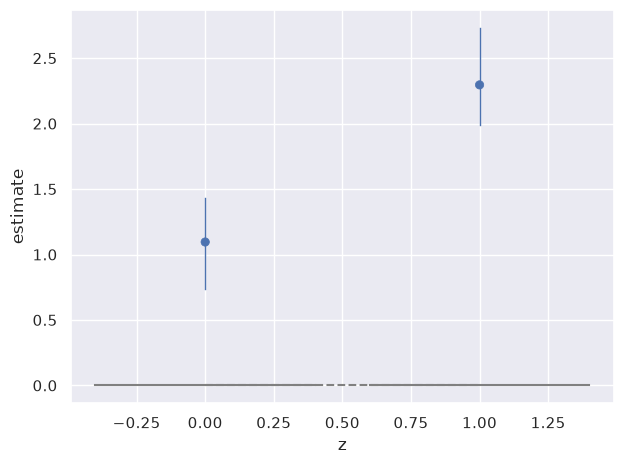

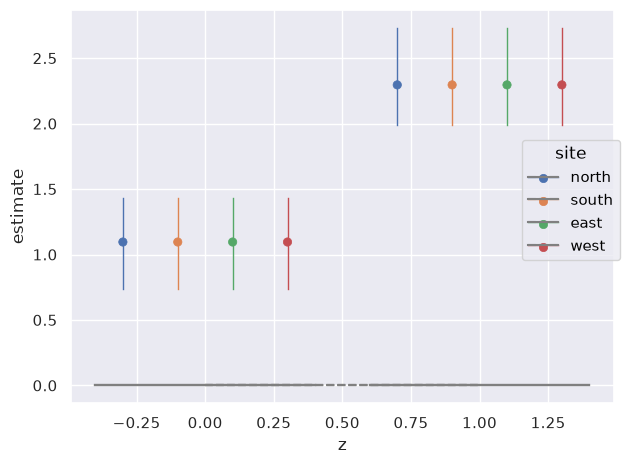

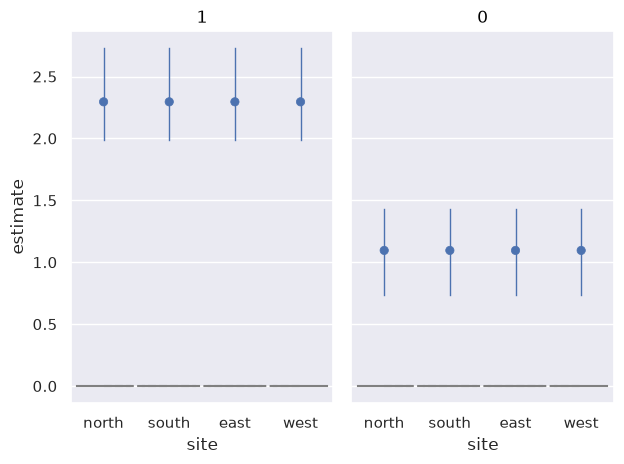

In [7]:
cate = gaussian_effect("cate", conditional={"z": [0, 1]})
gate = gaussian_effect("gate", average_by=["z", "site"])
print(cate.summary)
print(gate.summary)
plot_effects(cate, main="z").show()
plot_effects(gate, main="z", group="site").show()
plot_effects(gate, main="site", panel="z").show()


## Weights and dose-response curves

Reference weights change the target population. They are normalized within each
selected ATT/ATU/CATE/GATE population, not once before selecting rows. Negative,
non-finite or all-zero weights are invalid. These weights are not propensity scores
and do not make this a doubly robust estimator.

A dose-response curve keeps the same reference people at every explicit dose. Its
causal interpretation additionally requires support for those interventions. We
stay inside the observed dose range. No extrapolation warning can establish overlap
in a real application.


   term estimand  comparison  reference  value  n_reference  weight_sum  \
0  dose      ate  difference        0.0    1.0          128       260.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.381678    1.092234     1.638055  
   term       estimand comparison reference  value  n_reference  weight_sum  \
0  dose  dose_response       mean      None    0.0          128       128.0   
1  dose  dose_response       mean      None    0.5          128       128.0   
2  dose  dose_response       mean      None    1.0          128       128.0   

   estimate  lower_3.0%  upper_97.0%  
0  0.512851    0.346456     0.689017  
1  1.351267    1.233668     1.445720  
2  2.189684    2.045132     2.347639  
   term       estimand  comparison  reference  value  n_reference  weight_sum  \
0  dose  dose_response  difference        0.0    0.0          128       128.0   
1  dose  dose_response  difference        0.0    0.5          128       128.0   
2  dose  dose_response  difference        0.0    1.0   

/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):


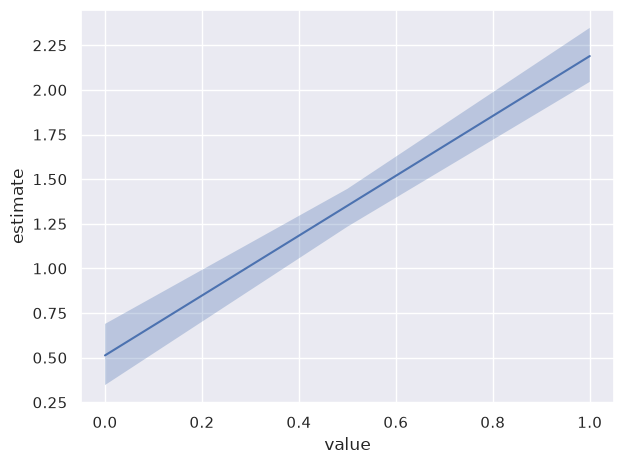

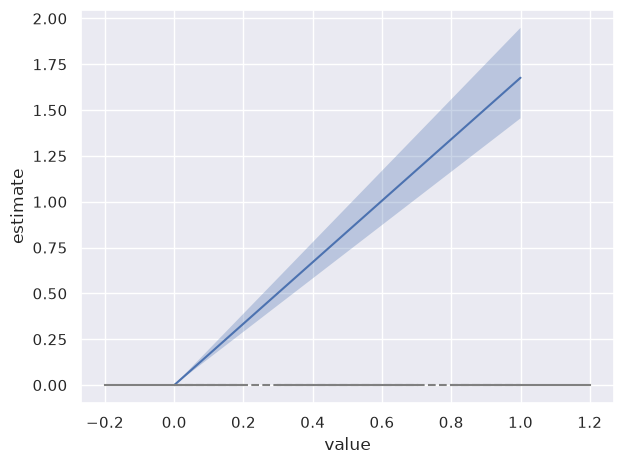

In [8]:
weights = np.where(reference["z"].to_numpy() == 0, 3.0, 1.0)
weighted_ate = gaussian_effect("ate", weights=weights)
dose_response = gaussian_effect("dose_response", values=[0.0, 0.5, 1.0])
print(weighted_ate.summary)
print(dose_response.summary)
dose_contrasts = gaussian_effect(
    "dose_response", values=[0.0, 0.5, 1.0], reference_value=0.0,
)
print(dose_contrasts.summary)
plot_effects(dose_response, main="value").show()
plot_effects(dose_contrasts, main="value").show()


### Hand-worked heterogeneity example

This is independent arithmetic, **not another fit or a mocked model result**.
With $m(a,z)=0.5+(1+3z)a+2z$, original $(A,Z)=[(0,0),(1,1)]$ gives ATE 2.5,
ATT 4 and ATU 1. Weights $(3,1)$ change ATE to 1.75. The standardized means at
$a=(0,1,3)$ are $(1.5,4,9)$. These identities explain why target-population choices
matter; sampling estimates above are not required to equal these unrelated numbers.


In [9]:
z_math = np.array([0.0, 1.0])
means_math = lambda a: 0.5 + (1 + 3 * z_math) * a + 2 * z_math
unit_effect_math = means_math(1) - means_math(0)
np.testing.assert_allclose(unit_effect_math.mean(), 2.5)
np.testing.assert_allclose(unit_effect_math[1], 4.0)
np.testing.assert_allclose(unit_effect_math[0], 1.0)
np.testing.assert_allclose(np.average(unit_effect_math, weights=[3, 1]), 1.75)
np.testing.assert_allclose([means_math(a).mean() for a in [0, 1, 3]], [1.5, 4, 9])


## A named binary event: risks, risk difference, RR and OR

For the second genuine fit, the event is conversion. We use a categorical response
with named levels. The fitted model, not an alphabetical assumption, determines the
success event. We read that exact level, and also request its complement explicitly.
Treatment is binary here, so original membership can be inferred for ATT/ATU when
the supplied two intervention levels match the two observed levels.


In [10]:
nb = 160
xb = rng.normal(size=nb)
zb = rng.integers(0, 2, size=nb)
ab = rng.binomial(1, expit(-0.2 + 0.4 * xb), size=nb)
probability = expit(-0.7 + 0.8 * ab + 0.5 * xb + 0.7 * zb)
converted = np.where(rng.binomial(1, probability), "converted", "not_converted")
binary_data = pd.DataFrame({
    "converted": pd.Categorical(converted, categories=["converted", "not_converted"]),
    "exposure": ab, "x": xb, "z": zb,
})
binary_model = bmb.Model(
    "converted ~ exposure + x + z", binary_data, family="bernoulli",
)
binary_idata = binary_model.fit(
    draws=250, tune=250, chains=2, cores=1,
    random_seed=105502, target_accept=0.95,
)
binary_posterior = dataset(binary_idata.posterior)
assert binary_posterior.sizes["chain"] == 2 and binary_posterior.sizes["draw"] == 250
print("Bernoulli posterior dimensions:", dict(binary_posterior.sizes))
event = binary_model.response_term.success
other_event = next(level for level in binary_data["converted"].cat.categories if level != event)
print("Actual modeled success:", event, "; opposite event:", other_event)
print("Bernoulli divergences:", int(dataset(binary_idata.sample_stats)["diverging"].sum()))
binary_inputs = dict(
    treatment="exposure", outcome="converted", adjustment_set=["x", "z"],
    temporal_order=["x", "z", "exposure", "converted"],
    reference_population=binary_data[["exposure", "x", "z"]].copy(deep=True),
    values=[0, 1], event=event,
)

def binary_effect(estimand="ate", comparison="difference", **kwargs):
    return g_computation(
        binary_model, binary_idata, estimand=estimand, comparison=comparison,
        **binary_inputs, **kwargs,
    )


Modeling the probability that converted==converted


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [Intercept, exposure, x, z]


Output()

Sampling 2 chains for 250 tune and 250 draw iterations (500 + 500 draws total) took 0 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Bernoulli posterior dimensions: {'chain': 2, 'draw': 250}
Actual modeled success: converted ; opposite event: not_converted
Bernoulli divergences: 0


For each draw, the risk difference is $M_s(1)-M_s(0)$, the risk ratio is
$M_s(1)/M_s(0)$, and the marginal odds ratio is
$[M_s(1)/(1-M_s(1))]/[M_s(0)/(1-M_s(0))]$. Summaries follow these draw-wise
operations. Averaging unit risk ratios, taking ratios of posterior means, or
exponentiating the exposure coefficient generally gives a different quantity.
Ratios are defined only for Bernoulli outcomes. Invalid denominators cause an error;
the function does not clip probabilities or discard troublesome draws.


       term estimand  comparison  reference  value  n_reference  weight_sum  \
0  exposure      ate  difference          0      1          160       160.0   

   estimate  lower_3.0%  upper_97.0%  
0  0.189648    0.056843     0.306951  
       term estimand  comparison  reference  value  n_reference  weight_sum  \
0  exposure      ate  risk_ratio          0      1          160       160.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.394514    1.087176     1.716231  
       term estimand  comparison  reference  value  n_reference  weight_sum  \
0  exposure      ate  odds_ratio          0      1          160       160.0   

   estimate  lower_3.0%  upper_97.0%  
0  2.351292    1.224811     3.725467  
       term estimand  comparison  reference  value  n_reference  weight_sum  \
0  exposure      att  risk_ratio          0      1           73        73.0   

   estimate  lower_3.0%  upper_97.0%  
0  1.365092    1.062896     1.645706  


/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  if not values or pd.Series(values).isna().any() or len(pd.unique(values)) != len(values):
/work/src/bambi/causal/validate.py:164: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and 

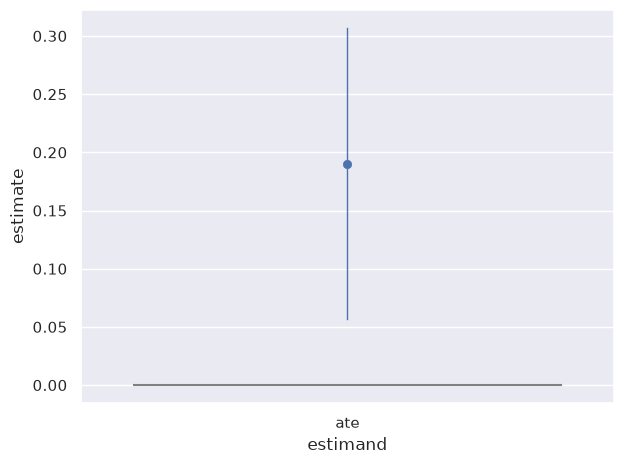

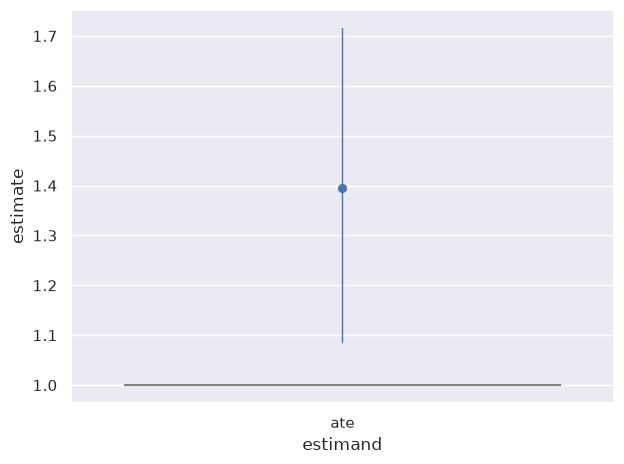

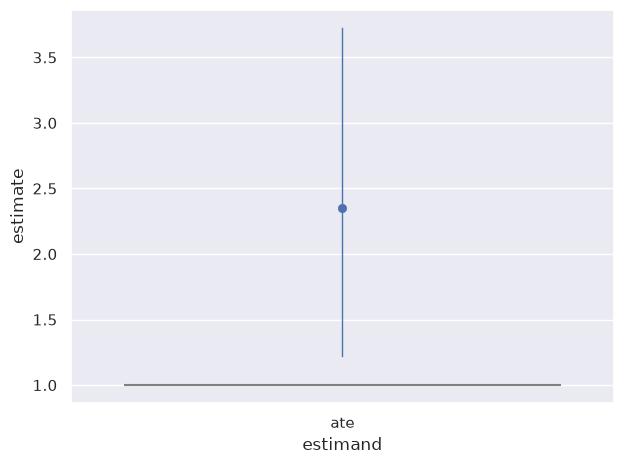

In [11]:
risk_difference = binary_effect()
risk_ratio = binary_effect(comparison="risk_ratio")
odds_ratio = binary_effect(comparison="odds_ratio")
print(risk_difference.summary)
print(risk_ratio.summary)
print(odds_ratio.summary)
# Population and scale are separate: this is a risk ratio among originally exposed people.
att_risk_ratio = binary_effect("att", comparison="risk_ratio")
print(att_risk_ratio.summary)

opposite_inputs = {**binary_inputs, "event": other_event}
opposite_difference = g_computation(
    binary_model, binary_idata, estimand="ate", **opposite_inputs,
)
np.testing.assert_allclose(
    opposite_difference.draws["effects"].ds["estimate"].values,
    -risk_difference.draws["effects"].ds["estimate"].values,
    rtol=1e-10, atol=1e-10,
)
plot_effects(risk_difference, main="estimand").show()
plot_effects(risk_ratio, main="estimand").show()
plot_effects(odds_ratio, main="estimand").show()


### Why the marginal odds ratio is not the coefficient

Another hand-worked example has unit reference risks $(1/10,4/5)$ and intervention
risks $(2/11,8/9)$. Both unit odds ratios equal 2. After equal-weight
standardization, the marginal odds ratio is $583/414$, and the risk ratio is
$1060/891$. This non-collapsibility is mathematics, not evidence of confounding.


In [12]:
p0_math = np.array([1 / 10, 4 / 5])
p1_math = np.array([2 / 11, 8 / 9])
unit_or_math = (p1_math / (1 - p1_math)) / (p0_math / (1 - p0_math))
m0_math, m1_math = p0_math.mean(), p1_math.mean()
marginal_rr_math = m1_math / m0_math
marginal_or_math = (m1_math / (1 - m1_math)) / (m0_math / (1 - m0_math))
np.testing.assert_allclose(unit_or_math, 2)
np.testing.assert_allclose(marginal_rr_math, 1060 / 891)
np.testing.assert_allclose(marginal_or_math, 583 / 414)
assert not np.isclose(marginal_or_math, 2)
print("Mean unit RR:", np.mean(p1_math / p0_math), "; marginal RR:", marginal_rr_math)


Mean unit RR: 1.4646464646464645 ; marginal RR: 1.1896745230078563


## Outcome scales and distributional parameters

The expected-outcome adapter supports the exact native Gaussian, Beta, Gamma,
Weibull, Exponential, LogNormal and ExGaussian families, plus Bernoulli event risk.
It does not assume that a likelihood's parent parameter is always its mean.

| Native family | Expected outcome |
|---|---|
| Gaussian, Beta, Gamma, Weibull, Exponential | $\mu$, using the native Bambi parametrization |
| LogNormal | $\exp(\mu+\sigma^2/2)$ |
| ExGaussian | $\mu+\nu$ |
| Bernoulli | the named success probability, or its complement for the opposite event |

For example, with distributional LogNormal `sigma`, each intervention must predict
both `mu` and `sigma` (respecting aliases) before converting to the outcome scale.
Holding sigma fixed or exponentiating only mu would target something else. The
following simple calculation illustrates that conversion; it is not a third fit
and does not attach artificial posterior draws to a fitted model.

Student-t, count/binomial, categorical/ordinal, circular, mixture/hurdle/zero-inflated,
custom and transformed/wrapped responses are explicitly unsupported here. In
particular, a constrained or truncated Gaussian does not retain Gaussian expectation
mu. Rejecting these cases is safer than returning a mislabeled causal effect.


In [13]:
mu_example = np.array([0.0, 0.4])
sigma_example = np.array([0.3, 0.8])
lognormal_means = np.exp(mu_example + sigma_example**2 / 2)
print("Outcome-scale LogNormal means:", lognormal_means)
print("Location-only exponentiation:", np.exp(mu_example))
assert not np.allclose(lognormal_means, np.exp(mu_example))


Outcome-scale LogNormal means: [1.04602786 2.05443321]
Location-only exponentiation: [1.        1.4918247]


## Interpretation and limits

- The causal declarations and adjustment checks cannot verify exchangeability,
  consistency, positivity or the absence of post-treatment bias. Explain why those
  assumptions are credible for the application before giving causal labels.
- CATE and GATE describe the stated conditional reference populations; they do not
  identify individual treatment effects. ATT/ATU are original-membership targets.
- These intervals reflect posterior model uncertainty given a fixed empirical
  population. They are not bootstrap intervals or uncertainty over population selection.
- Known-group predictions include the fitted group effects by default. Setting
  `include_group_specific=False` sets those effects to zero; it does not integrate
  over a distribution of new groups. Unseen groups retain the model's normal error.
- The computation does not change the caller's training data, reference population
  or posterior, refit transformations, or add prediction noise. Real test coverage
  must establish these invariants; the notebook is an explanation, not their proof.

In a real study, report the intervention pair, event, covariates and their temporal
roles, reference population and weights, group-effect choice, overlap limitations,
sampler diagnostics, and the assumptions required for identification alongside the
chosen effect scale.
